# Notebook 1: Mutual Information con señales simples

Este notebook está pensado para introducir la **intuición de información mutua (MI)** usando señales acústicas muy simples.

La idea es responder una pregunta central:

> **¿Qué variable acústica contiene más información sobre la clase de sonido?**

Trabajaremos con tres clases sintéticas:
- seno de 200 Hz
- seno de 400 Hz
- ruido blanco

Luego extraeremos variables simples y calcularemos su información mutua con la clase.

## 1. Librerías

Usaremos únicamente herramientas sencillas de Python, NumPy, SciPy, Matplotlib y scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import periodogram
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import KBinsDiscretizer

print("Todo funciona bien")

np.random.seed(42)

Todo funciona bien


## 2. Parámetros generales

Definimos frecuencia de muestreo, duración y cantidad de señales por clase.

In [2]:
fs = 4000          # frecuencia de muestreo [Hz]
duration = 1.0     # duración [s]
n_samples = int(fs * duration)
t = np.arange(n_samples) / fs

n_per_class = 80
classes = ['sine_200', 'sine_400', 'white_noise']

## 3. Generación de señales

Crearemos señales con una pequeña variabilidad en amplitud y una pequeña cantidad de ruido para que el ejercicio sea más realista.

In [3]:
def generate_signal(label, fs, t):
    amp = np.random.uniform(0.7, 1.0)
    noise_level = np.random.uniform(0.01, 0.05)
    
    if label == 'sine_200':
        x = amp * np.sin(2 * np.pi * 200 * t)
    elif label == 'sine_400':
        x = amp * np.sin(2 * np.pi * 400 * t)
    elif label == 'white_noise':
        x = amp * np.random.randn(len(t))
    else:
        raise ValueError(f'Clase desconocida: {label}')
    
    x = x + noise_level * np.random.randn(len(t))
    return x

signals = []
labels = []

for c in classes:
    for _ in range(n_per_class):
        signals.append(generate_signal(c, fs, t))
        labels.append(c)

signals = np.array(signals)
labels = np.array(labels)

signals.shape, labels.shape

((240, 4000), (240,))

## 4. Visualización de ejemplos temporales

Veamos una señal de cada clase en el dominio del tiempo.

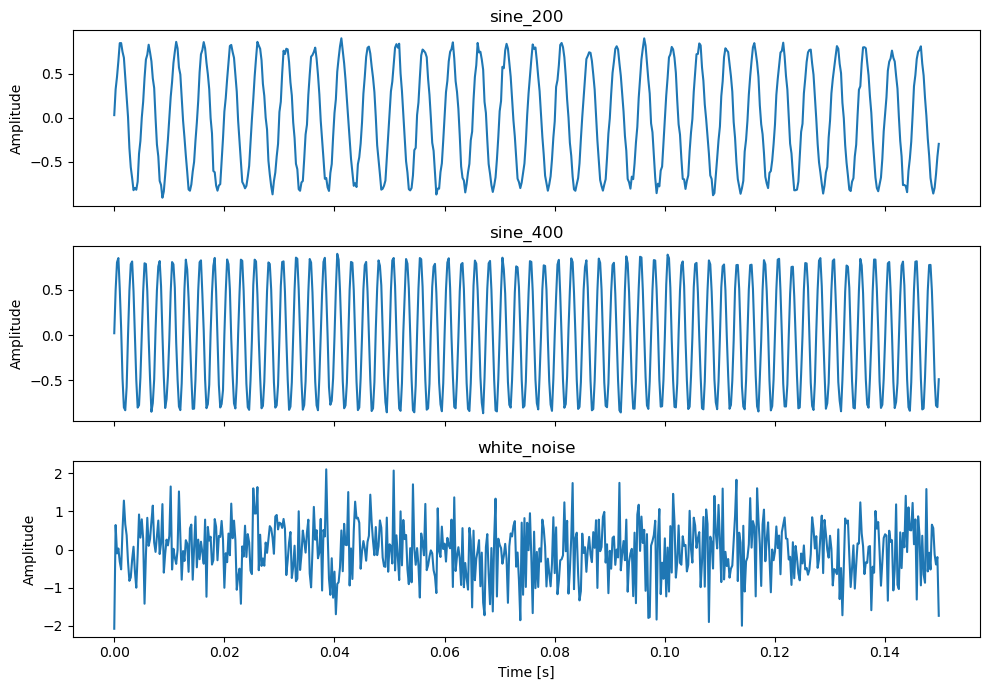

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)

for ax, c in zip(axes, classes):
    idx = np.where(labels == c)[0][0]
    ax.plot(t[:600], signals[idx][:600])
    ax.set_title(c)
    ax.set_ylabel('Amplitude')

axes[-1].set_xlabel('Time [s]')
plt.tight_layout()
plt.show()

## 5. Definición de variables acústicas simples

Extraeremos tres variables muy intuitivas:

1. **RMS energy**: nivel promedio de energía.
2. **Dominant frequency**: frecuencia con mayor energía en el espectro.
3. **Spectral entropy**: mide cuán "dispersa" está la energía espectral.

Estas variables son ideales para introducir MI porque son interpretables.

In [5]:
def rms_energy(x):
    return np.sqrt(np.mean(x**2))

def dominant_frequency(x, fs):
    freqs, psd = periodogram(x, fs=fs)
    return freqs[np.argmax(psd)]

def spectral_entropy(x, fs, eps=1e-12):
    freqs, psd = periodogram(x, fs=fs)
    p = psd / (np.sum(psd) + eps)
    h = -np.sum(p * np.log2(p + eps))
    return h

features = []
for x in signals:
    features.append([
        rms_energy(x),
        dominant_frequency(x, fs),
        spectral_entropy(x, fs),
    ])

features = np.array(features)
feature_names = ['rms_energy', 'dominant_frequency', 'spectral_entropy']

features[:5]

array([[5.75417033e-01, 2.00000000e+02, 1.31489279e-01],
       [7.02200363e-01, 2.00000000e+02, 4.10867381e-02],
       [6.28602921e-01, 2.00000000e+02, 8.29762081e-02],
       [5.97203733e-01, 2.00000000e+02, 1.25697013e-01],
       [6.33966111e-01, 2.00000000e+02, 7.80279668e-03]])

## 6. Visualización de las variables

Antes de calcular MI, es muy importante mirar cómo se distribuyen las variables por clase.

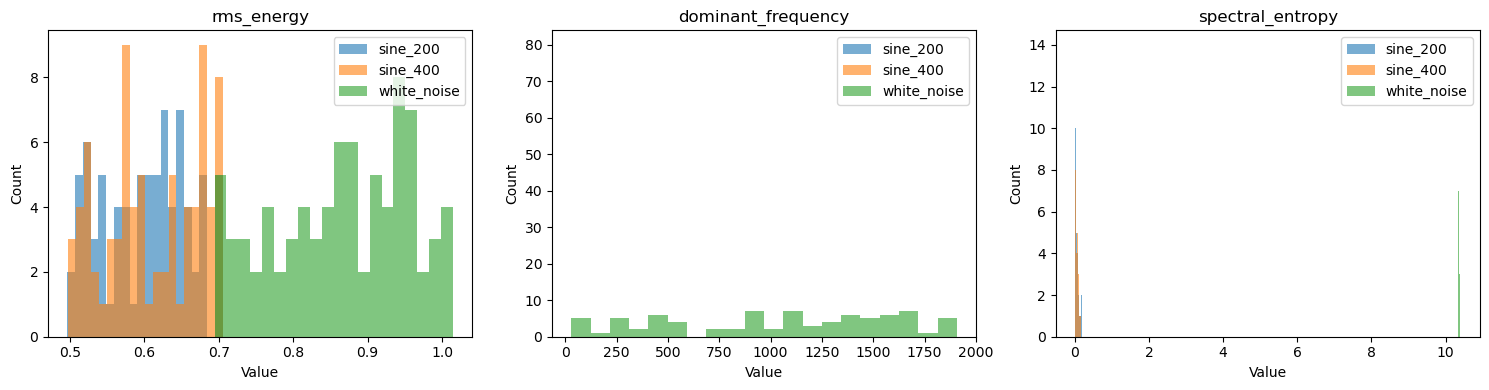

In [6]:
label_to_int = {c: i for i, c in enumerate(classes)}
y = np.array([label_to_int[l] for l in labels])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, ax in enumerate(axes):
    for c in classes:
        idx = labels == c
        ax.hist(features[idx, i], bins=20, alpha=0.6, label=c)
    ax.set_title(feature_names[i])
    ax.set_xlabel('Value')
    ax.set_ylabel('Count')
    ax.legend()

plt.tight_layout()
plt.show()

## 7. Cálculo de Mutual Information

Usaremos `mutual_info_classif` de scikit-learn para estimar cuánta información aporta cada variable respecto de la clase.

Interpretación general:
- **MI alta**: la variable ayuda mucho a distinguir clases.
- **MI baja**: la variable aporta poca información útil.

In [7]:
mi_scores = mutual_info_classif(features, y, discrete_features=False, random_state=42)

for name, score in zip(feature_names, mi_scores):
    print(f'{name:20s} -> MI = {score:.4f}')

rms_energy           -> MI = 0.6037
dominant_frequency   -> MI = 1.0446
spectral_entropy     -> MI = 0.6033


## 8. Ranking de variables por MI

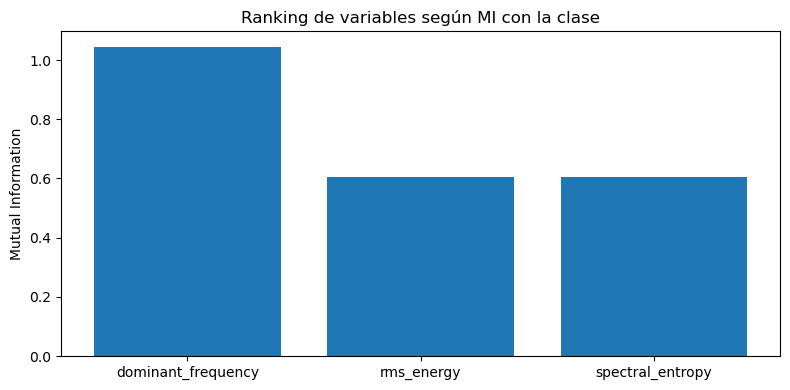

In [8]:
order = np.argsort(mi_scores)[::-1]

plt.figure(figsize=(8, 4))
plt.bar(np.array(feature_names)[order], mi_scores[order])
plt.ylabel('Mutual Information')
plt.title('Ranking de variables según MI con la clase')
plt.tight_layout()
plt.show()

## 9. Interpretación guiada

Preguntas para discutir con Juan:

1. ¿Qué variable obtuvo mayor MI?
2. ¿Tiene sentido físico/acústico ese resultado?
3. ¿Qué variable parece menos útil?
4. ¿La visualización de histogramas coincide con los valores de MI?

En este ejemplo, es esperable que la **frecuencia dominante** tenga una MI alta, porque separa muy bien el seno de 200 Hz y el de 400 Hz. También es esperable que el **ruido blanco** tenga un comportamiento distinto en frecuencia dominante y entropía espectral.

## 10. Extensión opcional: discretización manual

Como Juan tiene una base matemática fuerte, puede ser útil mirar una aproximación discreta.

Aquí discretizamos una variable continua en bins y volvemos a estimar su MI. Esto no reemplaza los estimadores continuos, pero ayuda a la intuición.

In [9]:
feature_idx = 1  # dominant_frequency
x = features[:, feature_idx].reshape(-1, 1)

kbd = KBinsDiscretizer(n_bins=8, encode='ordinal', strategy='quantile')
x_disc = kbd.fit_transform(x).ravel()

mi_disc = mutual_info_classif(x_disc.reshape(-1, 1), y, discrete_features=True, random_state=42)[0]
print(f'MI discretizada para {feature_names[feature_idx]} = {mi_disc:.4f}')

MI discretizada para dominant_frequency = 0.9301


/Users/vpoblete/miniconda3/envs/acus099_2026/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(
/Users/vpoblete/miniconda3/envs/acus099_2026/lib/python3.10/site-packages/sklearn/preprocessing/_discretization.py:397: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 0 are removed. Consider decreasing the number of bins.
  warnings.warn(


## 11. Conclusión

Este notebook deja instalada la intuición central:

> **La información mutua puede usarse para cuantificar cuánta información útil contiene una variable acústica respecto de una tarea de clasificación.**

Más adelante, la misma idea se puede extender desde variables simples a vectores de características, representaciones y embeddings.

## 12. Próximo paso sugerido

Notebook 2 podría avanzar hacia:

- variables acústicas extraídas desde audios reales,
- comparación entre varias features,
- introducción suave a vectores de características,
- y luego una transición natural al concepto de embedding.